In [2]:
import numpy as np
from optiland import optic

In [3]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file
from optiland.prescription import Prescription
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram
from optiland.diagnostics import check_system
from optiland.optic import Optic
from optiland.solves import QuickFocusSolve
from optiland.optimization import OptimizationProblem, OptimizerGeneric

In [105]:
wavelength = 0.633
fields = [0.1, 0.2, 0.3, 0.4, 0.5]

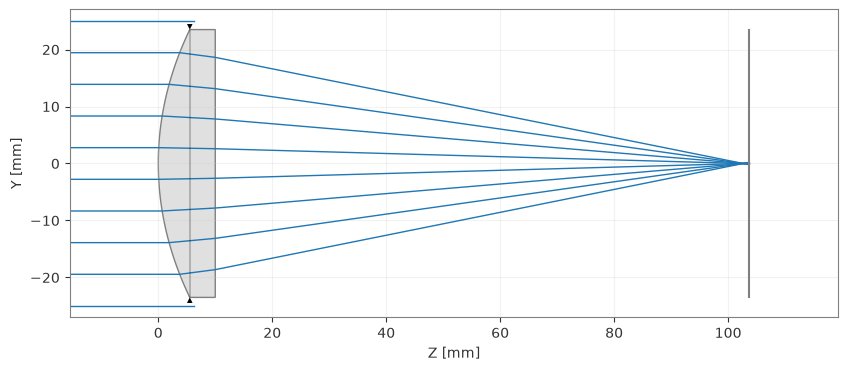

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [ ]:
EO16289 = load_zemax_file("C:/Users/saten/Documents/Umberto/OpticalEngineering/BeamReducer/zmx_16289.ZMX")
EO16289.wavelengths.remove(index = 0)
EO16289.wavelengths.add(value = wavelength)
EO16289.draw(num_rays=10)

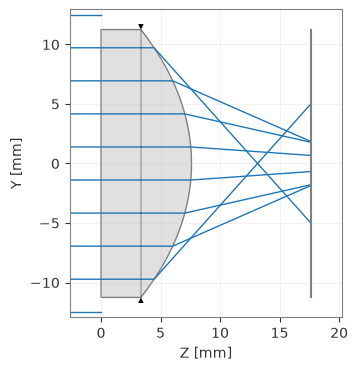

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [ ]:
EO16272 = load_zemax_file("C:/Users/saten/Documents/Umberto/OpticalEngineering/BeamReducer/zmx_16272.ZMX")
EO16272.wavelengths.remove(index = 0)
EO16272.wavelengths.add(value = wavelength)
EO16272.draw(num_rays=10)
#EO16272.surfaces[-1].thickness = 10

C:\Users\saten\AppData\Local\Temp\ipykernel_34304\1859955838.py:5: DeprecationWarning: Optic.set_thickness is deprecated and will be removed in v0.7.0; use optic.updater.set_thickness() instead.
  BeamReducer.set_thickness(300, surface_number=4)


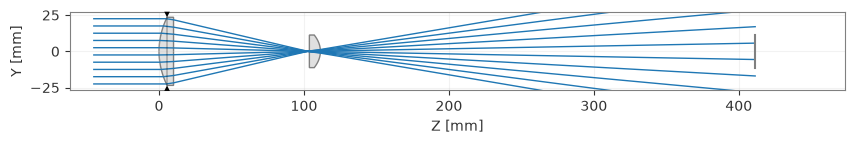

Surface 0: inf
Surface 1: 10.0
Surface 2: 93.72839477946492
Surface 3: 7.6
Surface 4: 300
Surface 5: 0.0


In [ ]:
BeamReducer = EO16289 + EO16272
BeamReducer.wavelengths.remove(index = 0)
BeamReducer.wavelengths.add(value = wavelength)
BeamReducer.set_aperture(aperture_type="EPD", value=45)
BeamReducer.set_thickness(300, surface_number=4)   
BeamReducer.draw(num_rays=10)
for i in range(len(BeamReducer.surfaces)):
    print(f"Surface {i}: {BeamReducer.surfaces[i].thickness}")


In [ ]:
problem = OptimizationProblem()

problem.add_variable(BeamReducer, "thickness", surface_number=2)

problem.add_operand(
    "AOI",
    target=0.0,
    weight=1.0,
    input_data={
        "optic": BeamReducer,
        "Hx": 0.0,
        "Hy": 0.0,
        "Px": 0.0,
        "Py": 1,
        "num_rings": 6,
        "wavelength": wavelength,
        "surface_number": -1,  # the image surface
    },
)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
OptimizerGeneric(problem).optimize(maxiter=10000)
print(f"Merit function after: {float(problem.sum_squared()):.6f}")

Merit function before: 91.747245
Merit function after: 0.000000


c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize(


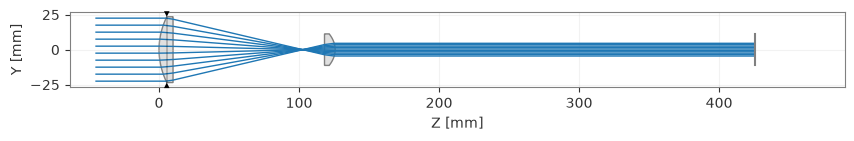

Surface 0: inf
Surface 1: 10.0
Surface 2: 108.18592832393608
Surface 3: 7.6
Surface 4: 300
Surface 5: 0.0
425.7859283239361


In [94]:
BeamReducer.draw(num_rays=10)
for i in range(len(BeamReducer.surfaces)):
    print(f"Surface {i}: {BeamReducer.surfaces[i].thickness}")
print(np.sum([s.thickness for s in BeamReducer.surfaces if np.isfinite(s.thickness)]))


Merit function before: 0.001037


c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize(


Merit function after: 0.000001
Surface 0: inf
Surface 1: 10.0
Surface 2: 108.18592832393608
Surface 3: 7.6
Surface 4: 300
Surface 5: 4.25
Surface 6: 7.517076793524125
Surface 7: 0.0


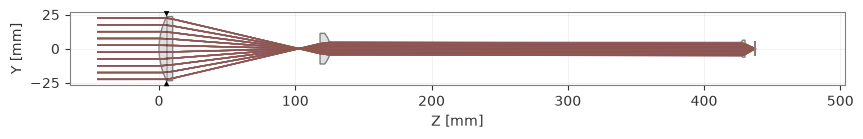

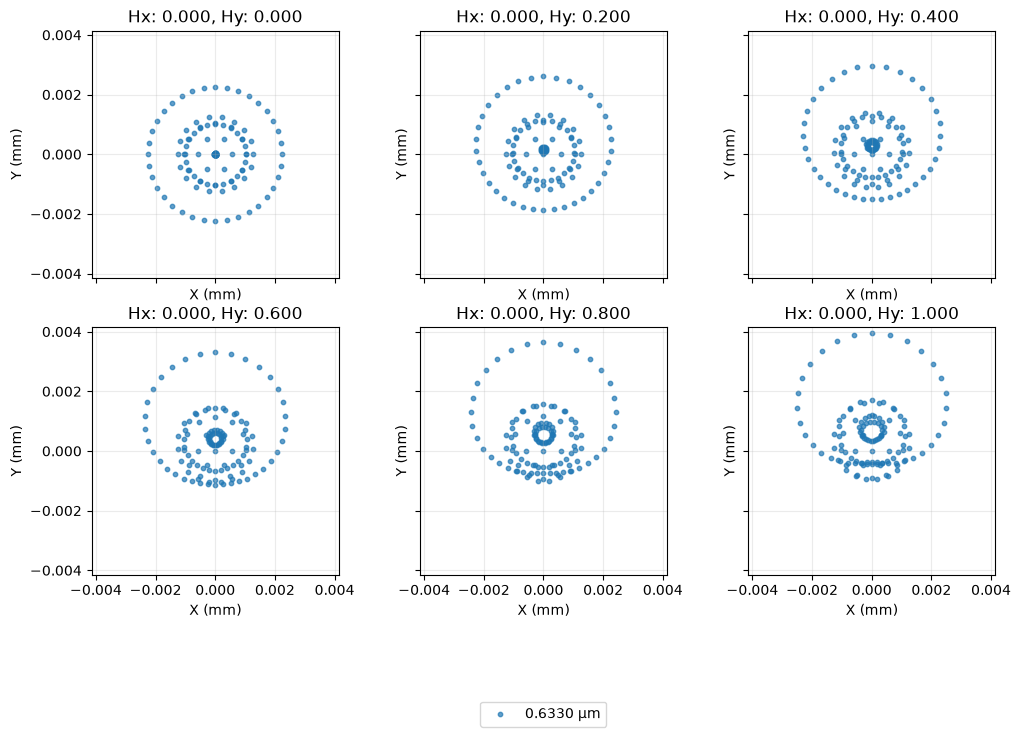

Optimized RMS spot radius by field (um):
[[np.float64(0.0014061324020541986)], [np.float64(0.0014159237551298498)], [np.float64(0.0014446377218464027)], [np.float64(0.0014904321290562144)], [np.float64(0.001550596575573327)], [np.float64(0.0016219638861383028)]]
Maximum ray radius by field (um):
[[np.float64(0.0022471728085913917)], [np.float64(0.0026106795089111956)], [np.float64(0.002965294208704339)], [np.float64(0.0033082836079566524)], [np.float64(0.0036365305398012304)], [np.float64(0.003946603342443344)]]
Centroid by field (um):
[(np.float64(-1.3987061727561027e-17), np.float64(-2.9241700924182275e-16)), (np.float64(-6.42967743788821e-16), np.float64(-0.004908959149586663)), (np.float64(3.055298796114112e-16), np.float64(-0.00981895814049642)), (np.float64(-5.555486079915646e-16), np.float64(-0.014731051688072413)), (np.float64(1.4642705246040452e-16), np.float64(-0.019646323366034)), (np.float64(-1.6565926233580092e-16), np.float64(-0.024565901008328474))]


In [114]:
FocusingOptics = load_zemax_file("C:/Users/saten/Downloads/AL1210-Zemax-ZMX.zmx")
FocusingOptics.wavelengths.remove(index = 0)
FocusingOptics.wavelengths.add(value = wavelength)
ReceiverBranch = BeamReducer + FocusingOptics

ReceiverBranch.fields.set_type(field_type="angle")
for i in range(len(fields)):
    ReceiverBranch.fields.add(180/np.pi * fields[i] / 1000)

problem = OptimizationProblem()

problem.add_variable(ReceiverBranch, "thickness", surface_number=6)

problem.add_operand(
    "rms_spot_size",
    target=0.0,
    weight=1.0,
    input_data={
        "optic": ReceiverBranch,
        "Hx": 0.0,
        "Hy": 0.0,
        "num_rings": 6,
        "wavelength": wavelength,
        "surface_number": -1,  # the image surface
    },
)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
OptimizerGeneric(problem).optimize(maxiter=200)
print(f"Merit function after: {float(problem.sum_squared()):.6f}")

for i in range(len(ReceiverBranch.surfaces)):
    print(f"Surface {i}: {ReceiverBranch.surfaces[i].thickness}")

ReceiverBranch.draw(num_rays=10)

spot = SpotDiagram(ReceiverBranch, num_rings = 6, fields = "all")
spot.view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())
print("Maximum ray radius by field (um):")
print(spot.geometric_spot_radius())
print("Centroid by field (um):")
print(spot.centroid())